## Power Analysis 

This notebook answers three questions before we commit resources:

- Do we have enough clients to detect a meaningful effect? (Sample sizing)
- What's the smallest lift we'd be able to detect? (MDE)
- How long do we need to run? (Duration analysis)

If any answer is "no" or "too long," we redesign before burning 90 days of experiment time.


**Part 1 (Prospective):** Before the experiment runs. Uses only historical trading data and planned sample sizes to answer: *Do we have enough clients? How long should we run? What's the smallest effect we can detect?*

**Part 2 (Post-Hoc):** After the experiment. Validates our planning assumptions against actual results and checks whether analytical formulas held up against simulation.

**Key insight:** Volume data is heavy-tailed and autocorrelated; naive power calculations assuming normality overstate power. So, we use both analytical formulas (quick lower bound) and simulation-based power (honest answer from actual distribution).

[note to self](https://claude.ai/chat/0fa1f438-c3db-4143-a075-6d52317b2b14)

In [1]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from pathlib import Path
import sys
import IPython.display as display

import warnings
warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path(".").resolve().parent / "src"))
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
from analysis.power_analysis import (
    minimum_detectable_effect,
    required_sample_size,
    power_at_effect_size,
    power_curve_with_cuped,
    simulate_power,
    experiment_sizing_table,
    duration_power_tradeoff,
    power_report,
)
from config import N_CLIENTS

data_dir = Path("..") / "data"
clients = pd.read_csv(data_dir / "raw" / "clients.csv")
pre_activity = pd.read_csv(data_dir / "raw" / "pre_period_activity.csv")

# Calculate pre-experiment planning inputs
pre_volumes = pre_activity.groupby("client_id")["weekly_volume"].sum()
baseline_mean = pre_volumes.mean()
baseline_std = pre_volumes.std()

# Planned sample sizes — 50/50 split of our eligible population
n_t_planned = N_CLIENTS // 2  # 2500
n_c_planned = N_CLIENTS - n_t_planned  # 2500

# Prospective ρ: split-half correlation from pre-period only.
# We plan to use CUPED in analysis, so the power calculation needs an estimate
# of how much variance CUPED will remove. That depends on ρ(pre, post) which
# we don't have yet (the experiment hasn't run). Split-half correlation
# (weeks 1-6 vs 7-13) proxies this: if a client's volume is stable across
# two halves of the pre-period, it'll be stable across pre and post too.
pre_h1 = (
    pre_activity[pre_activity["week"] <= 6].groupby("client_id")["weekly_volume"].sum()
)
pre_h2 = (
    pre_activity[pre_activity["week"] > 6].groupby("client_id")["weekly_volume"].sum()
)
rho_prospective = pre_h1.corr(pre_h2)

# CUPED-adjusted standard deviation (prospective)
cuped_std_prospective = baseline_std * np.sqrt(1 - rho_prospective**2)
var_reduction_prospective = (1 - (cuped_std_prospective / baseline_std) ** 2) * 100

print("PRE-EXPERIMENT PLANNING INPUTS")
print(f"Eligible clients:             {N_CLIENTS:,}")
print(f"Planned split:                {n_t_planned:,} treatment/{n_c_planned:,} control")
print(
    f"Baseline volume:              ${baseline_mean:,.0f} ± ${baseline_std:,.0f} (13-week total)"
)
print(f"Prospective ρ:                {rho_prospective:.3f} (split-half, pre-period only)")
print(f"CUPED variance reduction:     {var_reduction_prospective:.0f}%")

PRE-EXPERIMENT PLANNING INPUTS
Eligible clients:             5,000
Planned split:                2,500 treatment/2,500 control
Baseline volume:              $133,342,440 ± $117,564,454 (13-week total)
Prospective ρ:                0.974 (split-half, pre-period only)
CUPED variance reduction:     95%


## 1. Prospective: Planning the Experiment

### 1.1. How Many Clients Do We Need?

The first question in any experiment: given the effect size we care about, how large must each arm be? This determines whether we even have enough eligible clients to run the experiment.

The bars show required total sample size for each target lift, with and without CUPED. The orange line marks our eligible pool (N=5,000). If a bar exceeds the line, we can't detect that effect — we'd need more clients or a better variance reduction strategy.

In [3]:
target_lifts = [0.03, 0.05, 0.08, 0.10, 0.15, 0.20, 0.25] # 3% to 25% lifts
sizing_rows = []

for lift in target_lifts:
    raw = required_sample_size(baseline_mean * lift, baseline_std)
    cuped = required_sample_size(baseline_mean * lift, cuped_std_prospective)
    sizing_rows.append({
        'lift_pct': lift * 100,
        'n_raw': raw['n_total'],
        'n_cuped': cuped['n_total'],
        'savings': raw['n_total'] - cuped['n_total']
    })

sizing_df = pd.DataFrame(sizing_rows)

fig = go.Figure()

fig.add_trace(go.Bar(
    x=[f"{r['lift_pct']:.0f}%" for _, r in sizing_df.iterrows()],
    y=sizing_df['n_raw'],
    name='Without CUPED',
    marker_color='#EF553B',
    text=sizing_df['n_raw'],
    textposition='outside',
    hovertemplate='%{x} lift<br>Need n=%{y:,}<extra>Raw</extra>'
))

fig.add_trace(go.Bar(
    x=[f"{r['lift_pct']:.0f}%" for _, r in sizing_df.iterrows()],
    y=sizing_df['n_cuped'],
    name='With CUPED (prospective ρ)',
    marker_color='#636EFA',
    text=sizing_df['n_cuped'],
    textposition='outside',
    hovertemplate='%{x} lift<br>Need n=%{y:,}<extra>CUPED</extra>'
))

fig.add_hline(y=N_CLIENTS, line_dash='dash', line_color='orange', line_width=2,
              annotation_text=f'Our eligible pool: N={N_CLIENTS:,}', annotation_position='top right')

fig.update_layout(
    title='Required Sample Size to Detect Each Effect (80% power, α=0.05)',
    xaxis_title='Minimum Detectable Lift',
    yaxis_title='Total Clients Needed',
    yaxis=dict(type='log'),
    template='plotly_white',
    barmode='group',
    width=850, height=480,
    legend=dict(x=0.7, y=0.95),
    margin=dict(t=60)
)

fig.show()

# Decision summary
print('\nDECISION')
for _, row in sizing_df.iterrows():
    feasible_raw = '✓' if row['n_raw'] <= N_CLIENTS else '✗'
    feasible_cuped = '✓' if row['n_cuped'] <= N_CLIENTS else '✗'
    print(f"{row['lift_pct']:5.0f}% lift: need {row['n_raw']:>8,} raw ({feasible_raw}) | {row['n_cuped']:>6,} CUPED ({feasible_cuped})")



DECISION
    3% lift: need 27,117.0 raw (✗) | 1,366.0 CUPED (✓)
    5% lift: need  9,763.0 raw (✗) |  492.0 CUPED (✓)
    8% lift: need  3,814.0 raw (✓) |  193.0 CUPED (✓)
   10% lift: need  2,441.0 raw (✓) |  123.0 CUPED (✓)
   15% lift: need  1,085.0 raw (✓) |   55.0 CUPED (✓)
   20% lift: need    611.0 raw (✓) |   31.0 CUPED (✓)
   25% lift: need    391.0 raw (✓) |   20.0 CUPED (✓)


In [5]:
# # plotting static image because github plotly rendering has issues
# import IPython.display as display
# fig.write_image("../reports/figures/sample_size_plot.png")
# display.display(display.Image("../reports/figures/sample_size_plot.png"))

### 1.2. MDE: The Smallest Effect We Can Detect

Given our planned N=5,000 (2,500 per arm) and CUPED with prospective ρ, what's the smallest lift that would be statistically significant 80% of the time?

This is the planning MDE — the effect size threshold below which our experiment is essentially blind.

In [30]:
mde_raw = minimum_detectable_effect(n_t_planned, n_c_planned, baseline_std)
mde_cuped = minimum_detectable_effect(n_t_planned, n_c_planned, cuped_std_prospective)

print("MINIMUM DETECTABLE EFFECT (PROSPECTIVE)")
print(f'{"Method":<20}{"MDE ($)":>15}    {"MDE (% lift)":>15} {"SE ($)":>15}')
print("-" * 72)
print(
    f'{"Raw":<25} ${mde_raw["mde_absolute"]:,.0f} {mde_raw["mde_absolute"]/baseline_mean*100:>14.1f}% ${mde_raw["se"]:>14,.0f}'
)
print(
    f'{"CUPED (ρ=" + f"{rho_prospective:.3f})":<25} ${mde_cuped["mde_absolute"]:,.0f} {mde_cuped["mde_absolute"]/baseline_mean*100:>14.1f}% ${mde_cuped["se"]:>14,.0f}'
)
print(
    f'\nCUPED reduces MDE by {(1 - mde_cuped["mde_absolute"]/mde_raw["mde_absolute"])*100:.0f}% (variance reduction: {var_reduction_prospective:.0f}%)'
)
print(
    f'With CUPED, we can detect lifts as small as {mde_cuped["mde_absolute"]/baseline_mean*100:.1f}%.'
)

MINIMUM DETECTABLE EFFECT (PROSPECTIVE)
Method                      MDE ($)       MDE (% lift)          SE ($)
------------------------------------------------------------------------
Raw                       $9,315,901            7.0% $     3,325,225
CUPED (ρ=0.974)           $2,090,440            1.6% $       746,163

CUPED reduces MDE by 78% (variance reduction: 95%)
With CUPED, we can detect lifts as small as 1.6%.


### 1.3. Power Curves: How Confident Are We?

The power curve shows: for each possible true effect size, what's the probability our experiment detects it? The vertical dashed lines mark each method's MDE (80% power threshold).

CUPED shifts the entire curve left — we detect smaller effects at the same power level.

In [31]:
curves = power_curve_with_cuped(
    baseline_std, n_t_planned, n_c_planned, rho_prospective, baseline_mean
)

fig = go.Figure()

# Raw power curve
fig.add_trace(
    go.Scatter(
        x=curves["pct_lift"],
        y=curves["power_raw"],
        mode="lines",
        name="Raw",
        line=dict(color="#EF553B", width=2.5),
        hovertemplate="Effect: %{x:.1f}% lift<br>Power: %{y:.1%}<extra>Raw</extra>",
    )
)

# CUPED power curve (prospective ρ)
fig.add_trace(
    go.Scatter(
        x=curves["pct_lift"],
        y=curves["power_cuped"],
        mode="lines",
        name=f"CUPED (prospective ρ={rho_prospective:.3f})",
        line=dict(color="#636EFA", width=2.5),
        hovertemplate="Effect: %{x:.1f}% lift<br>Power: %{y:.1%}<extra>CUPED</extra>",
    )
)

# 80% power line
fig.add_hline(
    y=0.80,
    line_dash="dot",
    line_color="gray",
    annotation_text="80% power",
    annotation_position="bottom right",
)

# MDE markers
mde_raw_pct = curves.attrs["mde_raw"] / baseline_mean * 100
mde_cuped_pct = curves.attrs["mde_cuped"] / baseline_mean * 100

fig.add_vline(
    x=mde_raw_pct,
    line_dash="dash",
    line_color="#EF553B",
    line_width=1,
    annotation_text=f"Raw MDE: {mde_raw_pct:.1f}%",
    annotation_position="top right",
    annotation_font_color="#EF553B",
)
fig.add_vline(
    x=mde_cuped_pct,
    line_dash="dash",
    line_color="#636EFA",
    line_width=1,
    annotation_text=f"CUPED MDE: {mde_cuped_pct:.1f}%",
    annotation_position="top left",
    annotation_font_color="#636EFA",
)

fig.update_layout(
    title="Power Curve: Raw vs CUPED (Prospective Planning)",
    xaxis_title="True Effect Size (% lift over baseline volume)",
    yaxis_title="Statistical Power (probability of detection)",
    yaxis=dict(range=[0, 1.05], tickformat=".0%"),
    template="plotly_white",
    width=850,
    height=500,
    legend=dict(x=0.7, y=0.3),
    margin=dict(t=60),
)

fig.show()

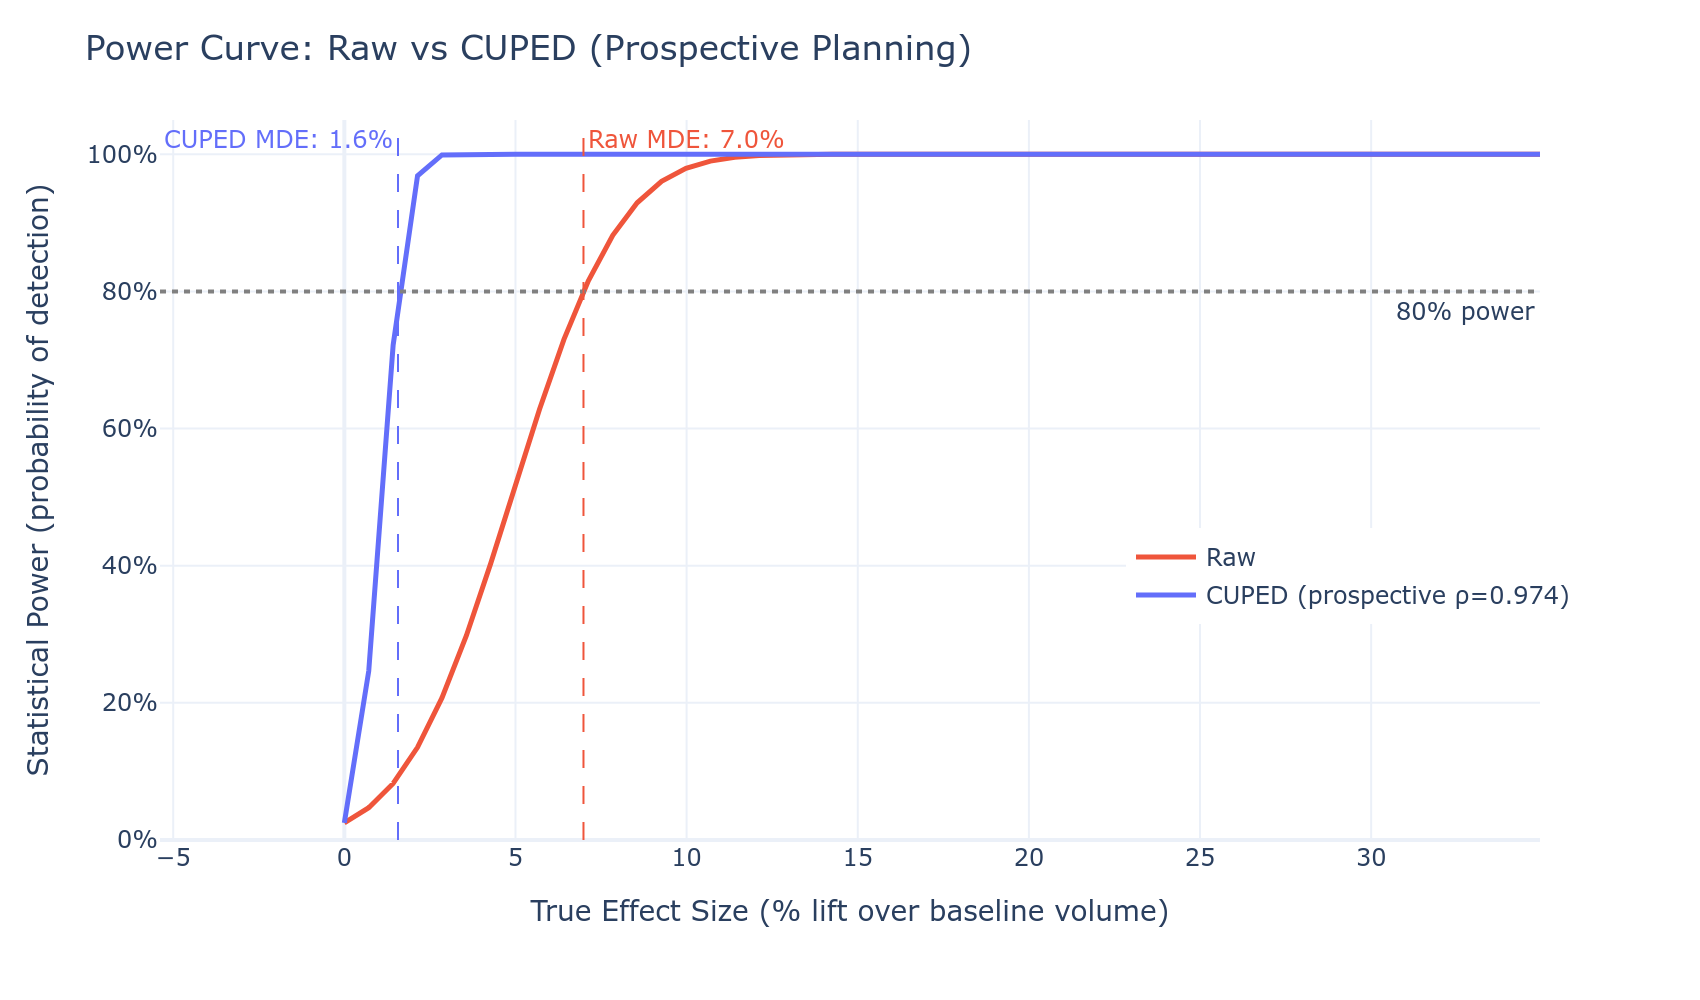

In [32]:
# plotting static image because github plotly rendering has issues
import IPython.display as display
fig.write_image("../reports/figures/power_curve.png", scale=2)
display.display(display.Image("../reports/figures/power_curve.png"))

### 1.4. Sizing Grid for Leadership

Leadership picks: "We want 80% power to detect a 10% lift — how many clients do we need?" This heatmap answers that question for every combination of sample size and effect size.

In [37]:
sizing = experiment_sizing_table(baseline_std, baseline_mean)

power_cols = [c for c in sizing.columns if c.startswith("power_at_")]
lift_labels = [
    c.replace("power_at_", "").replace("pct_lift", "% lift") for c in power_cols
]
z_data = sizing[power_cols].values

fig = go.Figure(
    data=go.Heatmap(
        z=z_data,
        x=lift_labels,
        y=[f"n={n} (MDE={m}%)" for n, m in zip(sizing["n_total"], sizing["mde_pct"])],
        colorscale="Darkmint",
        zmin=0,
        zmax=1,
        text=[[f"{v:.0%}" for v in row] for row in z_data],
        texttemplate="%{text}",
        textfont=dict(size=13),
        hovertemplate="Sample size: %{y}<br>Effect: %{x}<br>Power: %{z:.1%}<extra></extra>",
        colorbar=dict(title="Power", tickformat=".0%"),
    )
)

fig.update_layout(
    title="Experiment Sizing Grid: Power at Each (Sample Size × Effect Size)",
    xaxis_title="True Effect Size",
    yaxis_title="Total Sample Size (with MDE at 80% power)",
    template="plotly_white",
    width=800,
    height=450,
    margin=dict(t=60, l=180),
)

fig.show()

print(
    f"\nOur planned experiment uses N={N_CLIENTS:,}."
)


Our planned experiment uses N=5,000.


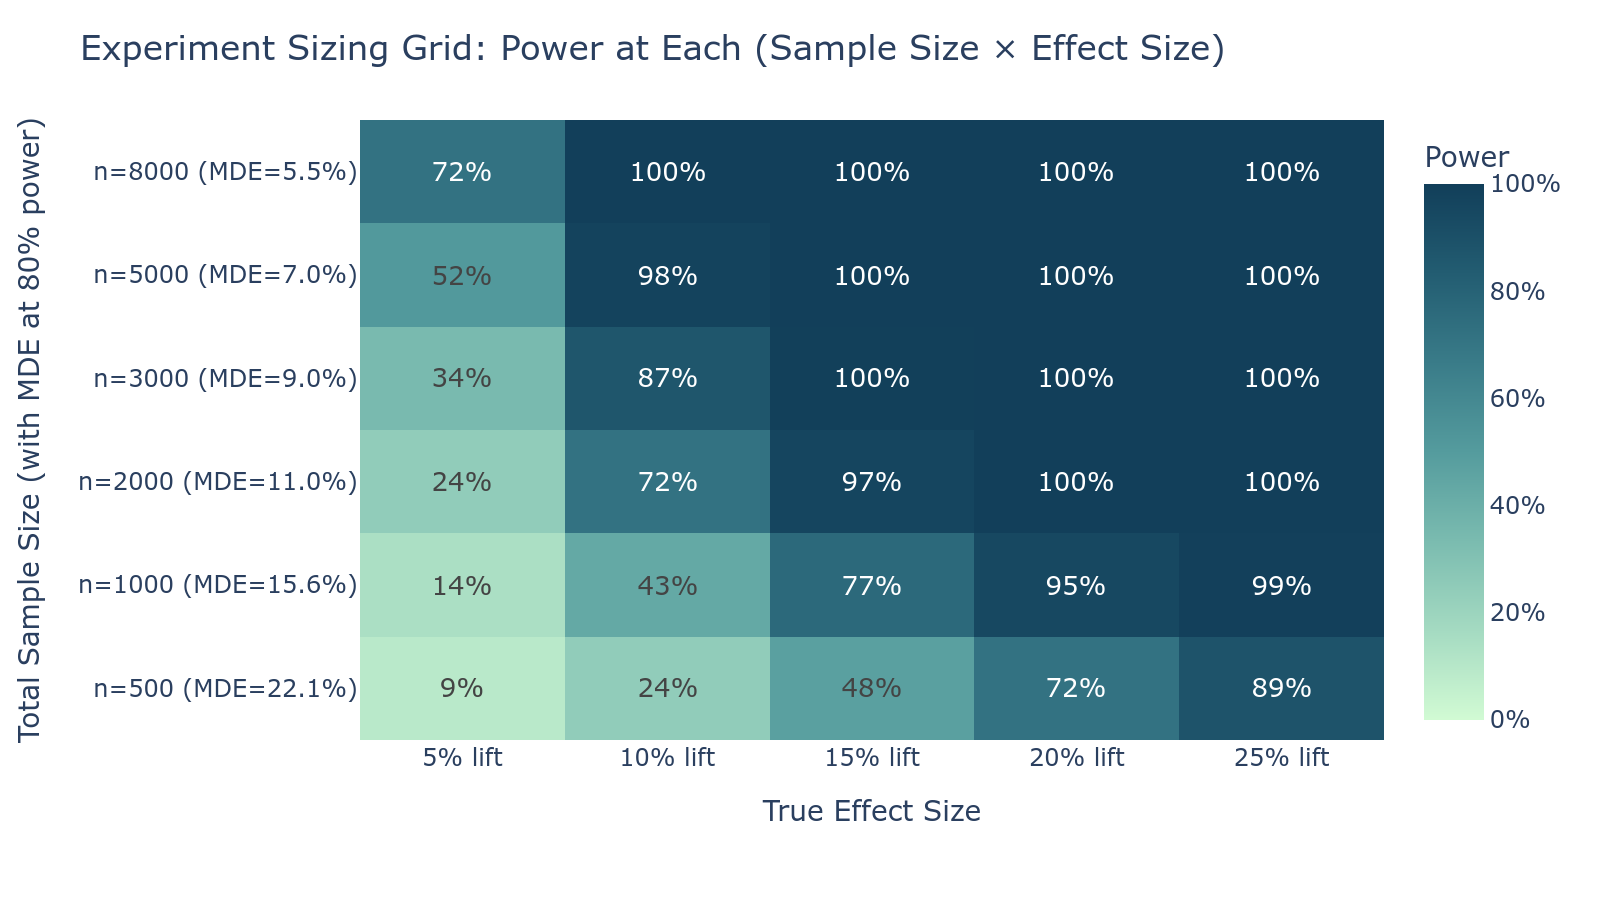

In [38]:
# plotting static image because github plotly rendering has issues
import IPython.display as display
fig.write_image("../reports/figures/heatmap.png", scale=2)
display.display(display.Image("../reports/figures/heatmap.png"))

### 1.5. Duration: Is 13 Weeks Enough?

Longer experiments reduce within-client noise (weekly fluctuations average out). But, longer experiments also cost more in holdout opportunity cost — control clients miss the intervention for longer. Where's the sweet spot?

The variance model: Var(W-week volume) = W²·σ²_between + W·σ²_within. Between-client variance (some trade $500M, others $10M) scales with W², while within-client noise (same client trades $50M one week, $80M the next) scales with W. So duration mainly helps when within-client noise is large relative to between-client differences.

In [41]:
duration = duration_power_tradeoff(
    pre_activity, n_t_planned, n_c_planned, effect_pct=0.10
)

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=["Power vs Duration (at 10% lift)", "MDE vs Duration"],
    horizontal_spacing=0.12,
)

fig.add_trace(
    go.Scatter(
        x=duration["weeks"],
        y=duration["power_at_target_effect"],
        mode="lines+markers",
        name="Power",
        line=dict(color="#636EFA", width=2.5),
        marker=dict(size=5),
        hovertemplate="Week %{x}<br>Power: %{y:.1%}<extra></extra>",
    ),
    row=1,
    col=1,
)

fig.add_hline(y=0.80, line_dash="dot", line_color="gray", row=1, col=1)
fig.add_vline(
    x=13,
    line_dash="dash",
    line_color="orange",
    line_width=1.5,
    annotation_text="Planned: 13 weeks",
    row=1,
    col=1,
)

fig.add_trace(
    go.Scatter(
        x=duration["weeks"],
        y=duration["mde_pct"],
        mode="lines+markers",
        name="MDE (%)",
        line=dict(color="#EF553B", width=2.5),
        marker=dict(size=5),
        hovertemplate="Week %{x}<br>MDE: %{y:.1f}%<extra></extra>",
    ),
    row=1,
    col=2,
)

fig.add_vline(x=13, line_dash="dash", line_color="orange", line_width=1.5, row=1, col=2)

fig.update_yaxes(title_text="Power", tickformat=".0%", row=1, col=1)
fig.update_yaxes(title_text="MDE (% lift)", row=1, col=2)
fig.update_xaxes(title_text="Experiment Duration (weeks)", row=1, col=1)
fig.update_xaxes(title_text="Experiment Duration (weeks)", row=1, col=2)

fig.update_layout(
    template="plotly_white", width=950, height=420, showlegend=False, margin=dict(t=60)
)

fig.show()

week13 = duration[duration["weeks"] == 13].iloc[0]
print(
    f'At 13 weeks: Power = {week13["power_at_target_effect"]:.0%}, MDE = {week13["mde_pct"]}%'
)
print(f"→ 13 weeks is sufficient for a 10% lift. Proceeding with one-quarter duration.")

At 13 weeks: Power = 98%, MDE = 7.0%
→ 13 weeks is sufficient for a 10% lift. Proceeding with one-quarter duration.


### 1.6. Subgroup Power: Where We'll Be Blind

Before we run, we should know which subgroup results to trust and which will be underpowered noise.

The mistake junior DSs make: slice data into subgroups, run tests, and report "not significant" as "no effect." But if a subgroup has n=50, it can't detect anything below a 30% lift. "Not significant" just means "too little data."

This table shows — **prospectively** — which segment results will be trustworthy and which require caution when interpreting.

In [6]:
# Merge pre-period volume onto client demographics
client_vols = clients[['client_id', 'segment', 'distance_bucket']].copy()
client_vols['pre_volume'] = client_vols['client_id'].map(pre_volumes)

# Compute subgroup power prospectively (planned 50/50 split, no group assignments yet)
sub_rows = []
for col in ['distance_bucket', 'segment']:
    for subgroup, sub_df in client_vols.groupby(col):
        n_sub = len(sub_df)
        n_t_sub = n_sub // 2
        n_c_sub = n_sub - n_t_sub
        sub_std = sub_df['pre_volume'].std()
        sub_mean = sub_df['pre_volume'].mean()

        if n_t_sub < 5 or n_c_sub < 5:
            continue

        mde_info = minimum_detectable_effect(n_t_sub, n_c_sub, sub_std)
        mde_pct = mde_info['mde_absolute'] / sub_mean * 100 if sub_mean > 0 else np.nan

        power_10 = power_at_effect_size(sub_mean * 0.10, n_t_sub, n_c_sub, sub_std)
        power_15 = power_at_effect_size(sub_mean * 0.15, n_t_sub, n_c_sub, sub_std)
        power_25 = power_at_effect_size(sub_mean * 0.25, n_t_sub, n_c_sub, sub_std)

        sub_rows.append({
            'cut': col, 'subgroup': subgroup, 'n_total': n_sub,
            'mde_pct': round(mde_pct, 2),
            'power_at_10pct_lift': round(power_10, 3),
            'power_at_15pct_lift': round(power_15, 3),
            'power_at_25pct_lift': round(power_25, 3),
            'adequately_powered': 'Yes' if mde_pct < 20 else 'No'
        })

all_subs = pd.DataFrame(sub_rows)

# Split by cut — one subplot each keeps bars readable
dist_df = all_subs[all_subs['cut'] == 'distance_bucket']
seg_df  = all_subs[all_subs['cut'] == 'segment']

LIFT_SERIES = [
    ('power_at_10pct_lift', '10% lift', '#EF553B'),
    ('power_at_15pct_lift', '15% lift', '#FFA15A'),
    ('power_at_25pct_lift', '25% lift', '#00CC96'),
]

fig = make_subplots(
    rows=1, cols=2,
    subplot_titles=['By Distance to Next Tier', 'By Client Segment'],
    horizontal_spacing=0.14,
)

for df_sub, col_idx in [(dist_df, 1), (seg_df, 2)]:
    for lift_col, lift_label, color in LIFT_SERIES:
        fig.add_trace(
            go.Bar(
                y=df_sub['subgroup'],
                x=df_sub[lift_col],
                name=lift_label,
                orientation='h',
                marker_color=color,
                showlegend=(col_idx == 1),
                hovertemplate='%{y}<br>Power: %{x:.1%}<extra>' + lift_label + '</extra>',
            ),
            row=1, col=col_idx,
        )

# 80% threshold line on each subplot
for col_idx in [1, 2]:
    fig.add_vline(x=0.80, line_dash='dash', line_color='grey', line_width=1.5,
                  row=1, col=col_idx)

# Dummy trace so threshold appears in legend
fig.add_trace(go.Scatter(
    x=[None], y=[None], mode='lines',
    line=dict(dash='dash', color='grey', width=1.5),
    name='80% threshold', showlegend=True,
))

fig.update_xaxes(range=[0, 1.0], tickformat='.0%', title_text='Statistical Power')
fig.update_layout(
    title='Prospective Subgroup Power (Planned 50/50 Split)',
    template='plotly_white',
    barmode='group',
    width=1050, height=500,
    legend=dict(orientation='h', x=0.28, y=-0.18),
    margin=dict(t=80, b=100, l=140),
)
fig.show()

# Print the MDE table
for cut_name in ['distance_bucket', 'segment']:
    cut_df = all_subs[all_subs['cut'] == cut_name]
    print(f'\n=== {cut_name.replace("_", " ").title()} Power ===')
    print(cut_df[['subgroup', 'n_total', 'mde_pct', 'power_at_10pct_lift',
                   'power_at_15pct_lift', 'power_at_25pct_lift', 'adequately_powered']].to_string(index=False))

# Warnings
underpowered = all_subs[all_subs['adequately_powered'] == 'No']
if len(underpowered) > 0:
    print('\n⚠ UNDERPOWERED SUBGROUPS — treat results with caution:')
    for _, row in underpowered.iterrows():
        print(f"  {row['subgroup']}: MDE = {row['mde_pct']:.0f}% (n={row['n_total']})")
else:
    print('\n→ All subgroups are adequately powered (MDE < 20%). Proceeding.')



=== Distance Bucket Power ===
   subgroup  n_total  mde_pct  power_at_10pct_lift  power_at_15pct_lift  power_at_25pct_lift adequately_powered
   10_to_20     1002    11.88                 0.66                 0.94                 1.00                Yes
    20_plus     3091     7.83                 0.95                 1.00                 1.00                Yes
at_top_tier      143    11.75                 0.66                 0.95                 1.00                Yes
  within_10      764    14.69                 0.48                 0.82                 1.00                Yes

=== Segment Power ===
          subgroup  n_total  mde_pct  power_at_10pct_lift  power_at_15pct_lift  power_at_25pct_lift adequately_powered
     Asset Manager      750    11.43                 0.69                 0.96                 1.00                Yes
Corporate Treasury     1250    12.30                 0.62                 0.93                 1.00                Yes
     Family Office      750  

---

## Part 2 — Post-Hoc: Was Our Design Adequate?

The experiment has run for 13 weeks. Now we validate: did our prospective power analysis hold up? We compare planned vs actual parameters and run simulation-based power to check the analytical formulas against the real (heavy-tailed) volume distribution.

In [ ]:
# ── Now load actual experiment data ──
df = pd.read_csv(data_dir / 'processed' / 'experiment_summary.csv')

n_t_actual = (df['group'] == 'treatment').sum()
n_c_actual = (df['group'] == 'control').sum()

# Post-hoc ρ: actual pre-post correlation (only available after experiment)
rho_posthoc = df[['pre_volume', 'post_volume']].corr().iloc[0, 1]
cuped_std_posthoc = baseline_std * np.sqrt(1 - rho_posthoc**2)
var_reduction_posthoc = (1 - (cuped_std_posthoc / baseline_std)**2) * 100

print('=== ACTUAL VS PLANNED ===')
print(f'{"Parameter":<30} {"Planned":>12} {"Actual":>12}')
print('-' * 56)
print(f'{"Treatment N":<30} {n_t_planned:>12,} {n_t_actual:>12,}')
print(f'{"Control N":<30} {n_c_planned:>12,} {n_c_actual:>12,}')
print(f'{"ρ (pre-post)":<30} {rho_prospective:>12.3f} {rho_posthoc:>12.3f}')
print(f'{"CUPED variance reduction":<30} {var_reduction_prospective:>11.0f}% {var_reduction_posthoc:>11.0f}%')

### Prospective vs Actual: How Close Were Our Assumptions?

The prospective split-half ρ slightly underestimates the actual pre-post ρ. This is expected — split-half uses 6–7 weeks per half (less data → more noise → lower correlation), while the actual pre-post spans two full 13-week periods. The practical impact is small: both give >95% variance reduction.

Below: a side-by-side comparison of MDE estimates and power curves using prospective vs actual parameters.

In [ ]:
# MDE comparison
mde_raw_actual = minimum_detectable_effect(n_t_actual, n_c_actual, baseline_std)
mde_cuped_prospective = minimum_detectable_effect(n_t_planned, n_c_planned, cuped_std_prospective)
mde_cuped_posthoc = minimum_detectable_effect(n_t_actual, n_c_actual, cuped_std_posthoc)

print('=== MDE COMPARISON ===')
print(f'{"Method":<35} {"MDE ($)":>15} {"MDE (% lift)":>12}')
print('-' * 64)
print(f'{"Raw (planned N=5000)":.<35} ${mde_raw["mde_absolute"]:>14,.0f} {mde_raw["mde_absolute"]/baseline_mean*100:>11.1f}%')
print(f'{"CUPED prospective (ρ=" + f"{rho_prospective:.3f})":.<35} ${mde_cuped_prospective["mde_absolute"]:>14,.0f} {mde_cuped_prospective["mde_absolute"]/baseline_mean*100:>11.1f}%')
print(f'{"CUPED post-hoc (ρ=" + f"{rho_posthoc:.3f})":.<35} ${mde_cuped_posthoc["mde_absolute"]:>14,.0f} {mde_cuped_posthoc["mde_absolute"]/baseline_mean*100:>11.1f}%')

# 3-line power curves: raw, CUPED prospective, CUPED post-hoc
curves_prosp = power_curve_with_cuped(baseline_std, n_t_planned, n_c_planned, rho_prospective, baseline_mean)
curves_posthoc = power_curve_with_cuped(baseline_std, n_t_actual, n_c_actual, rho_posthoc, baseline_mean)

fig = go.Figure()

# Raw
fig.add_trace(go.Scatter(
    x=curves_prosp['pct_lift'], y=curves_prosp['power_raw'],
    mode='lines', name='Raw',
    line=dict(color='#EF553B', width=2.5),
))

# CUPED prospective
fig.add_trace(go.Scatter(
    x=curves_prosp['pct_lift'], y=curves_prosp['power_cuped'],
    mode='lines', name=f'CUPED prospective (ρ={rho_prospective:.3f})',
    line=dict(color='#636EFA', width=2.5),
))

# CUPED post-hoc
fig.add_trace(go.Scatter(
    x=curves_posthoc['pct_lift'], y=curves_posthoc['power_cuped'],
    mode='lines', name=f'CUPED post-hoc (ρ={rho_posthoc:.3f})',
    line=dict(color='#636EFA', width=2.5, dash='dash'),
))

fig.add_hline(y=0.80, line_dash='dot', line_color='gray',
              annotation_text='80% power', annotation_position='bottom right')

mde_prosp_pct = curves_prosp.attrs['mde_cuped'] / baseline_mean * 100
mde_posthoc_pct = curves_posthoc.attrs['mde_cuped'] / baseline_mean * 100

fig.add_vline(x=mde_prosp_pct, line_dash='dash', line_color='#636EFA', line_width=1,
              annotation_text=f'Prospective MDE: {mde_prosp_pct:.1f}%', annotation_position='top right',
              annotation_font_color='#636EFA')
fig.add_vline(x=mde_posthoc_pct, line_dash='dot', line_color='#636EFA', line_width=1,
              annotation_text=f'Post-hoc MDE: {mde_posthoc_pct:.1f}%', annotation_position='bottom left',
              annotation_font_color='#636EFA')

fig.update_layout(
    title='Power Curves: Prospective Planning vs Post-Hoc Validation',
    xaxis_title='True Effect Size (% lift)',
    yaxis_title='Statistical Power',
    yaxis=dict(range=[0, 1.05], tickformat='.0%'),
    template='plotly_white',
    width=850, height=500,
    legend=dict(x=0.55, y=0.25),
    margin=dict(t=60)
)

fig.show()

print(f'\n→ Prospective MDE ({mde_prosp_pct:.1f}%) was slightly conservative vs post-hoc ({mde_posthoc_pct:.1f}%), as expected.')

### Simulation vs Analytical — The Reality Check

Analytical formulas assume normal distributions. Trading volume is log-normal with heavy tails — a few Market Makers trading $500M+ inflate variance massively. Simulation-based power uses the **actual** volume distribution and gives a more honest estimate.

Dashed lines = analytical formula. Dots = simulation with 95% CI. If dots fall below dashed lines, analytical formulas are overestimating power.

**Note:** Simulation-based CUPED power is inherently post-hoc — it uses the observed pre-post relationship to compute CUPED θ in each Monte Carlo draw.

In [ ]:
baseline_volumes = df['pre_volume'].values
pre_vols_for_cuped = df['pre_volume'].values

effect_sizes = [0.05, 0.10, 0.15, 0.20, 0.25]
sim_results = []

for eff in effect_sizes:
    sim_raw = simulate_power(baseline_volumes, eff, n_t_actual, n_c_actual, n_simulations=1000, seed=42)
    sim_cuped = simulate_power(baseline_volumes, eff, n_t_actual, n_c_actual, n_simulations=1000,
                                seed=42, use_cuped=True, pre_volumes=pre_vols_for_cuped)
    analytical_raw = power_at_effect_size(baseline_mean * eff, n_t_actual, n_c_actual, baseline_std)
    analytical_cuped = power_at_effect_size(baseline_mean * eff, n_t_actual, n_c_actual, cuped_std_posthoc)

    sim_results.append({
        'effect_pct': eff * 100,
        'analytical_raw': analytical_raw,
        'sim_raw': sim_raw['power'],
        'sim_raw_se': sim_raw['se_of_power'],
        'analytical_cuped': analytical_cuped,
        'sim_cuped': sim_cuped['power'],
        'sim_cuped_se': sim_cuped['se_of_power'],
    })

sim_df = pd.DataFrame(sim_results)

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=sim_df['effect_pct'], y=sim_df['analytical_raw'],
    mode='lines', name='Analytical (raw)',
    line=dict(color='#EF553B', width=2, dash='dash'),
))
fig.add_trace(go.Scatter(
    x=sim_df['effect_pct'], y=sim_df['analytical_cuped'],
    mode='lines', name='Analytical (CUPED)',
    line=dict(color='#636EFA', width=2, dash='dash'),
))

fig.add_trace(go.Scatter(
    x=sim_df['effect_pct'], y=sim_df['sim_raw'],
    mode='markers', name='Simulated (raw)',
    marker=dict(color='#EF553B', size=10, symbol='circle'),
    error_y=dict(type='data', array=sim_df['sim_raw_se'] * 1.96, visible=True),
    hovertemplate='%{x}% lift<br>Sim power: %{y:.1%}<extra>Sim (raw)</extra>'
))
fig.add_trace(go.Scatter(
    x=sim_df['effect_pct'], y=sim_df['sim_cuped'],
    mode='markers', name='Simulated (CUPED)',
    marker=dict(color='#636EFA', size=10, symbol='diamond'),
    error_y=dict(type='data', array=sim_df['sim_cuped_se'] * 1.96, visible=True),
    hovertemplate='%{x}% lift<br>Sim power: %{y:.1%}<extra>Sim (CUPED)</extra>'
))

fig.add_hline(y=0.80, line_dash='dot', line_color='gray')

fig.update_layout(
    title='Analytical vs Simulation-Based Power (1,000 Monte Carlo iterations)',
    xaxis_title='True Effect Size (% lift)',
    yaxis_title='Power',
    yaxis=dict(range=[0, 1.05], tickformat='.0%'),
    template='plotly_white',
    width=850, height=500,
    legend=dict(x=0.55, y=0.25),
    margin=dict(t=60)
)

fig.show()

### Full Power Report Summary

In [ ]:
report = power_report(df, pre_activity)

print('=' * 60)
print('POWER ANALYSIS SUMMARY')
print('=' * 60)
s = report['summary']
print(f"Sample:             {s['n_treatment']} treatment, {s['n_control']} control")
print(f"Baseline volume:    ${s['baseline_mean']:,.0f} ± ${s['baseline_std']:,.0f}")
print(f"MDE (raw):          {s['mde_raw_pct']:.1f}% lift")
print(f"MDE (CUPED):        {s['mde_cuped_pct']:.1f}% lift")
print(f"Pre-post ρ:         {report['pre_post_correlation']:.3f}")
print(f"CUPED var reduction: {report['variance_reduction_from_cuped_pct']:.0f}%")
print()

if report['underpowered_subgroups']:
    print('⚠ UNDERPOWERED SUBGROUPS (treat results with caution):')
    for msg in report['underpowered_subgroups']:
        print(msg)
else:
    print('All subgroups are adequately powered (MDE < 20%).')

print()
print('BOTTOM LINE: ', end='')
if s['mde_cuped_pct'] < 10:
    print(f'With CUPED, we can detect lifts as small as {s["mde_cuped_pct"]:.1f}%. Design is adequate.')
elif s['mde_raw_pct'] < 15:
    print(f'Without CUPED, we can detect ~{s["mde_raw_pct"]:.0f}% lifts. CUPED strongly recommended.')
else:
    print(f'MDE is {s["mde_raw_pct"]:.0f}% — we can only detect large effects. Consider more clients.')

print(f'\nNote: CUPED figures in the report above use post-hoc ρ = {rho_posthoc:.3f}.')
print(f'Prospective ρ (pre-period split-half) = {rho_prospective:.3f}.')